In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('cardekho_dataset.csv')
df.sample(10)


,Unnamed: 0,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
15076,19118,Maruti Celerio,Maruti,Celerio,3,47000,Dealer,Petrol,Automatic,21.63,998,67.05,5,525000
1206,1552,Hyundai Verna,Hyundai,Verna,13,120000,Individual,Diesel,Manual,16.80,1493,110.00,5,215000
11890,15091,Maruti Wagon R,Maruti,Wagon R,9,60000,Individual,Petrol,Manual,18.90,998,67.10,5,300000
3954,5034,Kia Seltos,Kia,Seltos,2,6000,Individual,Petrol,Manual,16.10,1353,138.00,5,1635000
12312,15610,Volkswagen Vento,Volkswagen,Vento,7,37540,Dealer,Petrol,Automatic,16.93,1197,103.20,5,565000
14498,18379,Hyundai Creta,Hyundai,Creta,3,47800,Individual,Petrol,Automatic,14.80,1591,121.30,5,1215000
14859,18842,Toyota Innova,Toyota,Innova,2,38000,Individual,Diesel,Manual,13.68,2393,147.80,8,1700000
411,532,Maruti Baleno,Maruti,Baleno,4,50000,Individual,Diesel,Manual,27.39,1248,74.00,5,560000
9215,11843,Honda City,Honda,City,5,78000,Dealer,Petrol,Automatic,18.00,1497,117.30,5,815000
13951,17698,Hyundai Creta,Hyundai,Creta,5,22000,Dealer,Petrol,Automatic,13.00,1591,121.30,5,1075000


Checking Missing valus

In [3]:
df.isnull().sum()

Unnamed: 0           0
car_name             0
brand                0
model                0
vehicle_age          0
km_driven            0
seller_type          0
fuel_type            0
transmission_type    0
mileage              0
engine               0
max_power            0
seats                0
selling_price        0
dtype: int64

EDA

In [4]:
## 1. Checking Rows and Column
df.shape


(15411, 14)

In [5]:
## Checking Types of Column
df.dtypes

Unnamed: 0             int64
car_name                 str
brand                    str
model                    str
vehicle_age            int64
km_driven              int64
seller_type              str
fuel_type                str
transmission_type        str
mileage              float64
engine                 int64
max_power            float64
seats                  int64
selling_price          int64
dtype: object

In [6]:
# 1. Duplicates check:
# Whole dataframe
print("Duplicates with all columns:", df.duplicated().sum())

# Duplicates ignoring 'Unnamed: 0'
feature_cols = [c for c in df.columns if c != 'Unnamed: 0']
dups_no_index = df.duplicated(subset=feature_cols).sum()
print("Duplicates ignoring 'Unnamed: 0':", dups_no_index)

# Duplicates ignoring price (same car listed multiple times with diff prices?)

car_features = [c for c in feature_cols if c != 'selling_price']
dups_car_only = df.duplicated(subset=car_features).sum()
print("Duplicates on car specs (ignoring selling_price):", dups_car_only)

# 2. Check invalid / unrealistic edge values

print("\n--- Summary of Numerical Min/Max ---")
num_cols = ['vehicle_age', 'km_driven', 'mileage', 'engine', 'max_power', 'seats', 'selling_price']
for c in num_cols:
    if c in df.columns:
        print(f"{c:15s}: min={df[c].min():<10} max={df[c].max():<10} (zeros: {(df[c] == 0).sum()})")

# Check specific anomalies

print("\n--- Specific Anomaly Checks ---")
print("Seats == 0:", (df['seats'] == 0).sum())
print("Seats distribution:\n", df['seats'].value_counts().sort_index())
print("\nMileage == 0:", (df['mileage'] == 0).sum())
print("Engine == 0:", (df['engine'] == 0).sum())
print("Max power == 0:", (df['max_power'] == 0).sum())
print("KM driven < 100:", (df['km_driven'] < 100).sum())
print("Selling price < 50,000:", (df['selling_price'] < 50000).sum())
print("Selling price > 10,000,000 (1 crore):", (df['selling_price'] > 10000000).sum())


Duplicates with all columns: 0
Duplicates ignoring 'Unnamed: 0': 167
Duplicates on car specs (ignoring selling_price): 1416

--- Summary of Numerical Min/Max ---
vehicle_age    : min=0          max=29         (zeros: 5)
km_driven      : min=100        max=3800000    (zeros: 0)
mileage        : min=4.0        max=33.54      (zeros: 0)
engine         : min=793        max=6592       (zeros: 0)
max_power      : min=38.4       max=626.0      (zeros: 0)
seats          : min=0          max=9          (zeros: 2)
selling_price  : min=40000      max=39500000   (zeros: 0)

--- Specific Anomaly Checks ---
Seats == 0: 2
Seats distribution:
 seats
0        2
2        7
4       77
5    12910
6      127
7     1922
8      311
9       55
Name: count, dtype: int64

Mileage == 0: 0
Engine == 0: 0
Max power == 0: 0
KM driven < 100: 0
Selling price < 50,000: 2
Selling price > 10,000,000 (1 crore): 7


In [7]:
## Data Cleaning: Duplicates & Invalid Edge Records

# 1. Drop unnecessary index column
if 'Unnamed: 0' in df.columns:
    df.drop(columns=['Unnamed: 0'], inplace=True)

# 2. Remove duplicate listings
initial_len = len(df)
df.drop_duplicates(inplace=True)
print(f"Removed {initial_len - len(df)} duplicate records.")

# 3. Fix 0-seat anomalies (Honda City & Nissan Kicks are 5-seaters)
df.loc[df['seats'] == 0, 'seats'] = 5

# 4. Remove scraping corruption (where km_driven was populated with selling_price)
df = df[df['km_driven'] != df['selling_price']].copy()
df.reset_index(drop=True, inplace=True)

print(f"Final cleaned dataset shape: {df.shape}")


Removed 167 duplicate records.
Final cleaned dataset shape: (15222, 13)


In [8]:
## Unique value in categorical Column
cat_cols = df.select_dtypes(include=['object','string']).columns

for col in cat_cols:
    unique_values = df[col].unique().tolist()
    print(f"{col} : {unique_values}")
     

car_name : ['Hyundai Grand', 'Hyundai i20', 'Maruti Alto', 'Ford Ecosport', 'Maruti Wagon R', 'Hyundai i10', 'Hyundai Venue', 'Maruti Swift', 'Hyundai Verna', 'Renault Duster', 'Mini Cooper', 'Maruti Ciaz', 'Mercedes-Benz C-Class', 'Toyota Innova', 'Maruti Baleno', 'Maruti Swift Dzire', 'Volkswagen Vento', 'Hyundai Creta', 'Honda City', 'Mahindra Bolero', 'Toyota Fortuner', 'Renault KWID', 'Honda Amaze', 'Hyundai Santro', 'Mahindra XUV500', 'Mahindra KUV100', 'Maruti Ignis', 'Datsun RediGO', 'Mahindra Scorpio', 'Mahindra Marazzo', 'Ford Aspire', 'Ford Figo', 'Maruti Vitara', 'Tata Tiago', 'Volkswagen Polo', 'Kia Seltos', 'Maruti Celerio', 'Datsun GO', 'BMW 5', 'Honda CR-V', 'Ford Endeavour', 'Mahindra KUV', 'Honda Jazz', 'BMW 3', 'Audi A4', 'Tata Tigor', 'Maruti Ertiga', 'Tata Safari', 'Mahindra Thar', 'Tata Hexa', 'Land Rover Rover', 'Maruti Eeco', 'Audi A6', 'Mercedes-Benz E-Class', 'Audi Q7', 'BMW Z4', 'BMW 6', 'Jaguar XF', 'BMW X5', 'MG Hector', 'Honda Civic', 'Isuzu D-Max', 'Porsc

In [9]:
# Unique values + count in categorical columns

cat_cols = df.select_dtypes(include='object').columns

for col in cat_cols:
    print(f"{col} : {df[col].nunique()}")

car_name : 121
brand : 32
model : 120
seller_type : 3
fuel_type : 5
transmission_type : 2


C:\Users\harish\AppData\Local\Temp\ipykernel_24908\2930259870.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include='object').columns


## Main Graphes

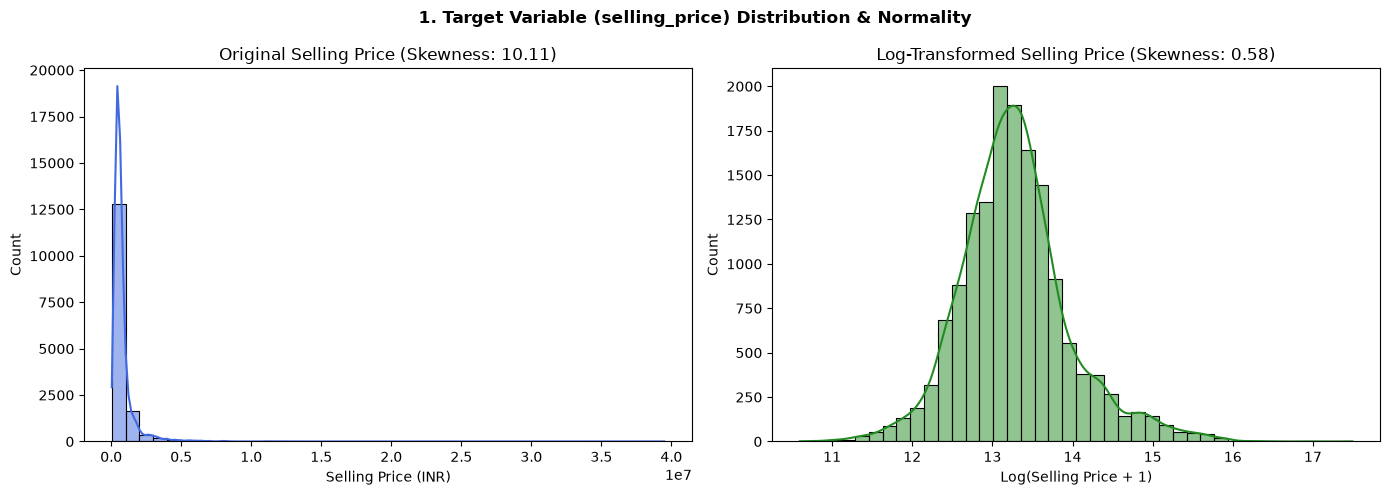

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("1. Target Variable (selling_price) Distribution & Normality", fontweight="bold")
# Raw Distribution
sns.histplot(df['selling_price'], kde=True, ax=axes[0], color='royalblue', bins=40)
axes[0].set_title(f"Original Selling Price (Skewness: {df['selling_price'].skew():.2f})")
axes[0].set_xlabel("Selling Price (INR)")
# Log-Transformed Distribution
log_price = np.log1p(df['selling_price'])
sns.histplot(log_price, kde=True, ax=axes[1], color='forestgreen', bins=40)
axes[1].set_title(f"Log-Transformed Selling Price (Skewness: {log_price.skew():.2f})")
axes[1].set_xlabel("Log(Selling Price + 1)")
plt.tight_layout()
plt.show()

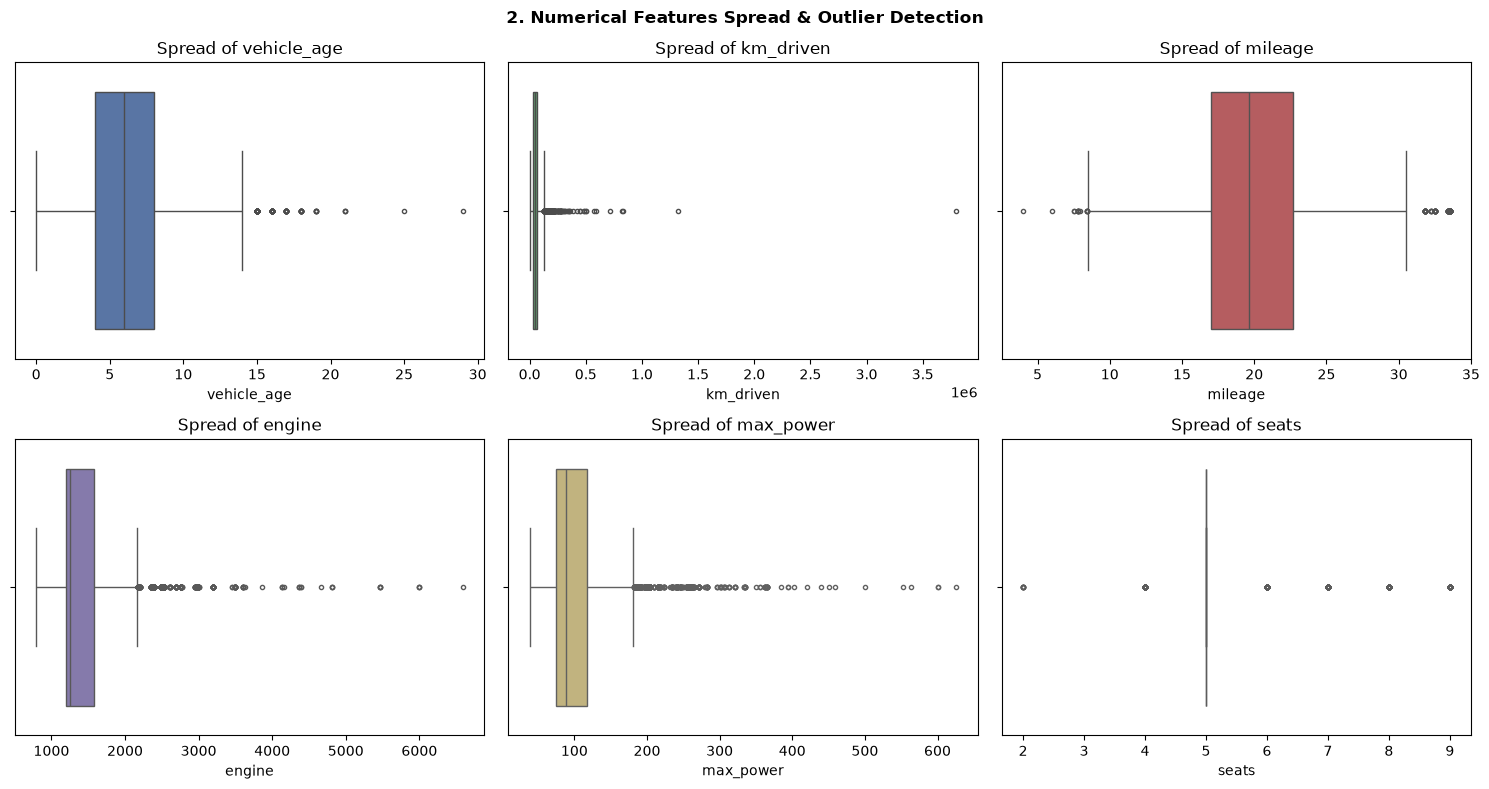

In [11]:
##  All Numerical Features Spread & Outliers
num_cols = ['vehicle_age', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle("2. Numerical Features Spread & Outlier Detection", fontweight="bold")
axes = axes.flatten()
colors = ['#4c72b0', '#55a868', '#c44e52', '#8172b3', '#ccb974', '#64b5cd']

for i, col in enumerate(num_cols):
    sns.boxplot(x=df[col], ax=axes[i], color=colors[i], fliersize=3)
    axes[i].set_title(f"Spread of {col}")
    axes[i].set_xlabel(col)

plt.tight_layout()
plt.show()


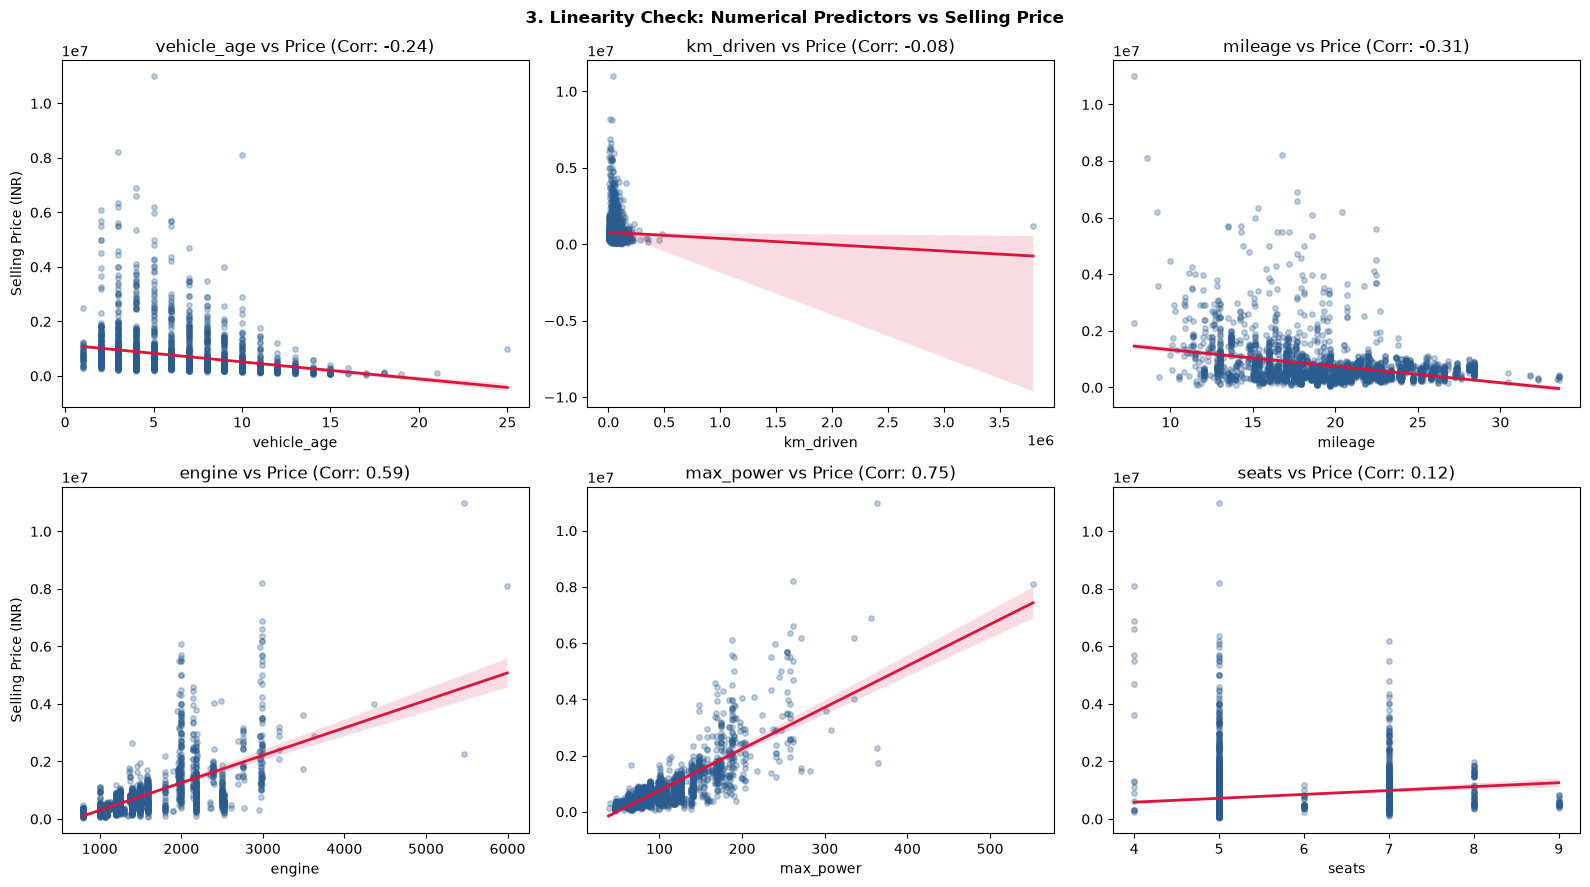

In [12]:
##  Linearity & Correlation with Target (selling_price)
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle("3. Linearity Check: Numerical Predictors vs Selling Price", fontweight="bold")
axes = axes.flatten()

# Sample for clear visualization
plot_sample = df.sample(min(3000, len(df)), random_state=42)

for i, col in enumerate(num_cols):
    sns.regplot(
        data=plot_sample,
        x=col,
        y='selling_price',
        ax=axes[i],
        scatter_kws={'alpha': 0.3, 's': 15, 'color': '#2b5c8f'},
        line_kws={'color': 'crimson', 'linewidth': 2}
    )
    corr_val = df[col].corr(df['selling_price'])
    axes[i].set_title(f"{col} vs Price (Corr: {corr_val:.2f})")
    axes[i].set_ylabel("Selling Price (INR)" if i % 3 == 0 else "")

plt.tight_layout()
plt.show()


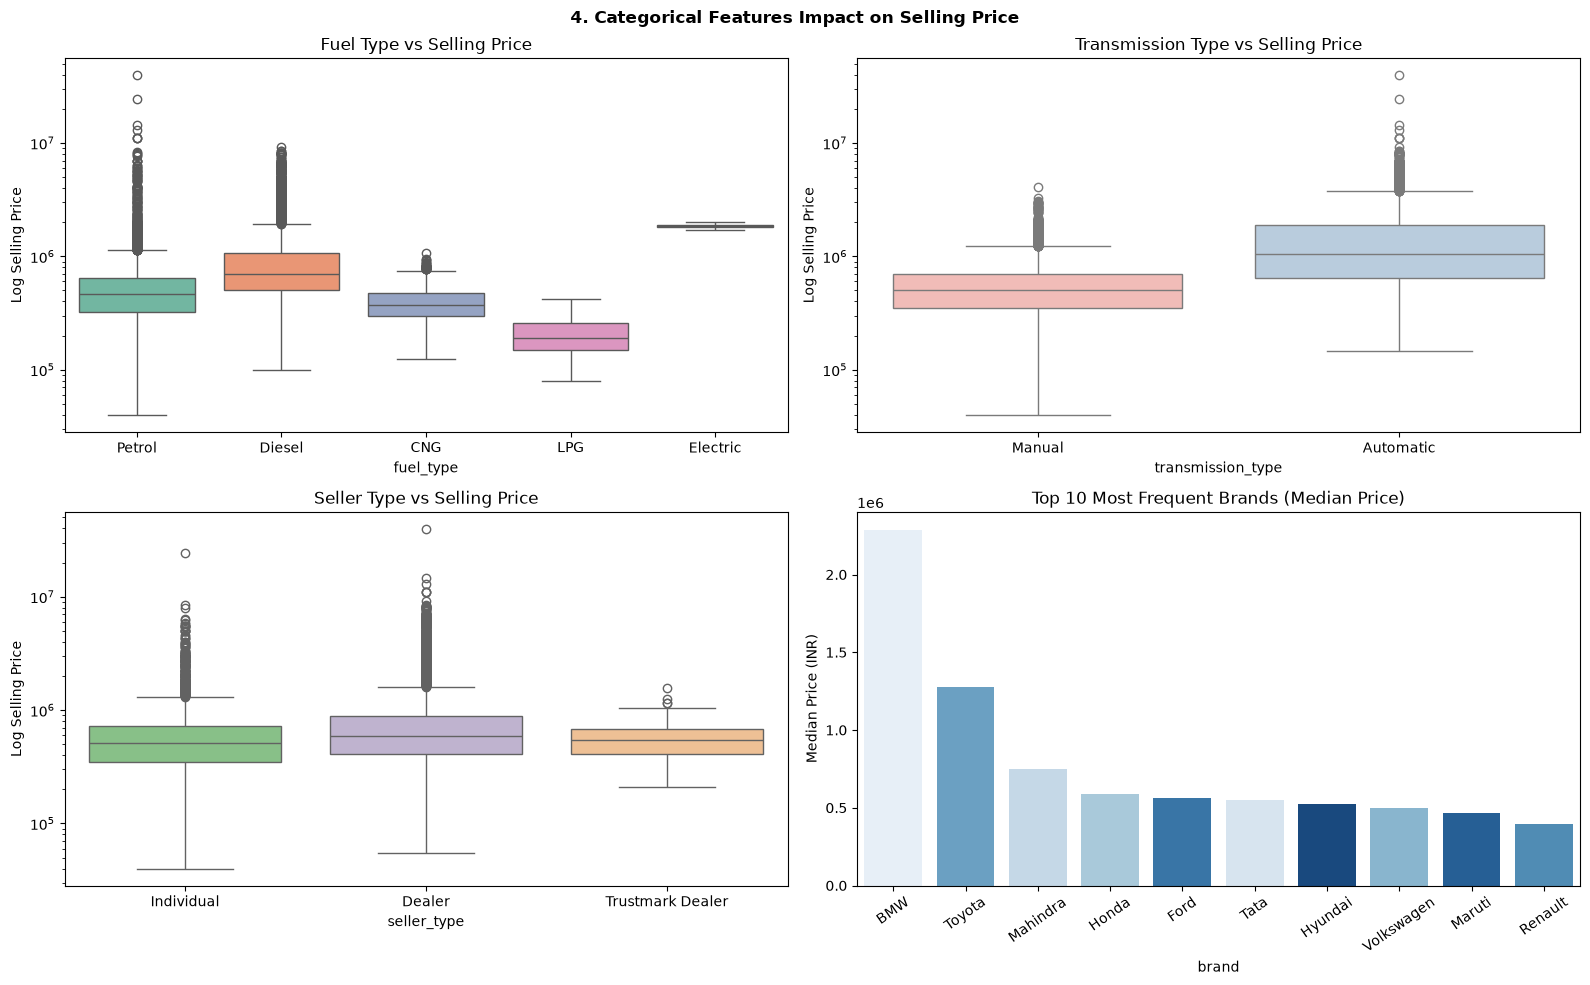

In [26]:
## Categorical Predictors Impact on Price
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle("4. Categorical Features Impact on Selling Price", fontweight="bold")

# 1. Fuel Type
sns.boxplot(data=df, x='fuel_type', y='selling_price', hue='fuel_type', ax=axes[0, 0], palette="Set2", legend=False)
axes[0, 0].set_title("Fuel Type vs Selling Price")
axes[0, 0].set_yscale('log')
axes[0, 0].set_ylabel("Log Selling Price")

# 2. Transmission Type
sns.boxplot(data=df, x='transmission_type', y='selling_price', hue='transmission_type', ax=axes[0, 1], palette="Pastel1", legend=False)
axes[0, 1].set_title("Transmission Type vs Selling Price")
axes[0, 1].set_yscale('log')
axes[0, 1].set_ylabel("Log Selling Price")

# 3. Seller Type
sns.boxplot(data=df, x='seller_type', y='selling_price', hue='seller_type', ax=axes[1, 0], palette="Accent", legend=False)
axes[1, 0].set_title("Seller Type vs Selling Price")
axes[1, 0].set_yscale('log')
axes[1, 0].set_ylabel("Log Selling Price")

# 4. Top 10 Most Frequent Brands (Sorted by Median Price)
top10_brands = df['brand'].value_counts().nlargest(10).index
brand_order = df[df['brand'].isin(top10_brands)].groupby('brand')['selling_price'].median().sort_values(ascending=False).index

sns.barplot(
    data=df[df['brand'].isin(top10_brands)],
    x='brand',
    y='selling_price',
    hue='brand',
    order=brand_order,
    estimator=np.median,
    errorbar=None,
    ax=axes[1, 1],
    palette="Blues_r",
    legend=False
)
axes[1, 1].set_title("Top 10 Most Frequent Brands (Median Price)")
axes[1, 1].tick_params(axis='x', rotation=35)
axes[1, 1].set_ylabel("Median Price (INR)")

plt.tight_layout()
plt.show()


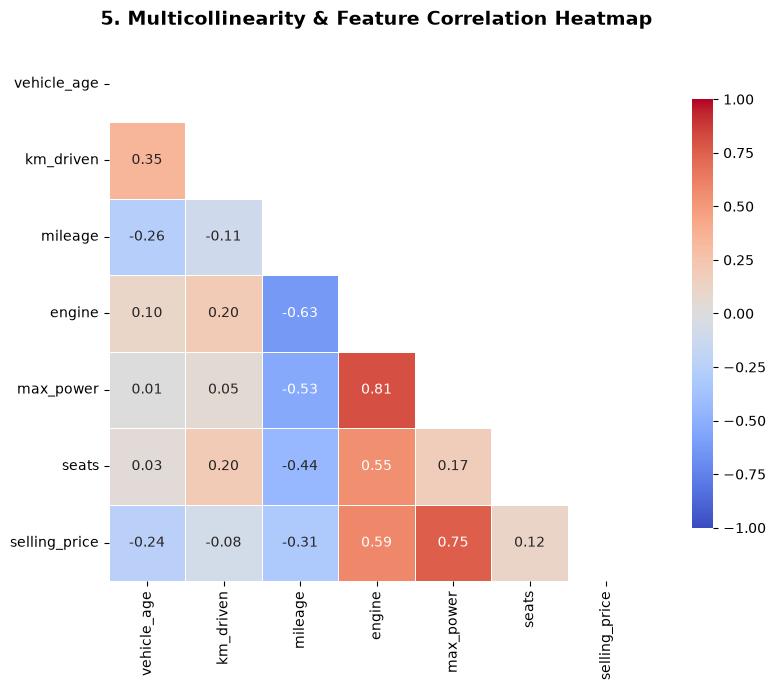

In [14]:
## Multicollinearity & Correlation Heatmap
plt.figure(figsize=(10, 7))
numeric_df = df.select_dtypes(include=['number'])
if 'Unnamed: 0' in numeric_df.columns:
    numeric_df = numeric_df.drop(columns=['Unnamed: 0'])

corr_matrix = numeric_df.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)
plt.title("5. Multicollinearity & Feature Correlation Heatmap", fontsize=14, fontweight="bold", pad=15)
plt.tight_layout()
plt.show()


## Train Test Split

In [15]:
# Drop target + all irrelevant/redundant columns
cols_to_drop = ['selling_price', 'Unnamed: 0', 'car_name', 'brand']

X = df.drop(columns=cols_to_drop, errors='ignore')
y = df['selling_price']

In [16]:
from sklearn.model_selection import train_test_split


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [17]:
df.shape

(15222, 13)

## handling Categorical data

In [27]:
## Applying Ohe in (fuel_type, seller_type, model) and Ordinal in transmission_type
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

num_cols = ['vehicle_age', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']

ct = ColumnTransformer(
    transformers=[
        ('num_scalar',StandardScaler(),num_cols),
        ('ohe', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), ['fuel_type', 'seller_type', 'model']),
        ('binary', OrdinalEncoder(categories=[['Manual', 'Automatic']]), ['transmission_type'])
    ],
    remainder='drop'
)

# Fit on X_train, transform both
X_train_encoded = ct.fit_transform(X_train)
X_test_encoded = ct.transform(X_test)


c:\Users\harish\Desktop\Python\Linear_regression\venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


In [28]:
# View the names of all transformed columns:
print(ct.get_feature_names_out())

# Check shapes
print("Train shape:", X_train_encoded.shape)
print("Test shape:", X_test_encoded.shape)


['num_scalar__vehicle_age' 'num_scalar__km_driven' 'num_scalar__mileage'
 'num_scalar__engine' 'num_scalar__max_power' 'num_scalar__seats'
 'ohe__fuel_type_Diesel' 'ohe__fuel_type_Electric' 'ohe__fuel_type_LPG'
 'ohe__fuel_type_Petrol' 'ohe__seller_type_Individual'
 'ohe__seller_type_Trustmark Dealer' 'ohe__model_5' 'ohe__model_6'
 'ohe__model_7' 'ohe__model_A4' 'ohe__model_A6' 'ohe__model_A8'
 'ohe__model_Alto' 'ohe__model_Altroz' 'ohe__model_Alturas'
 'ohe__model_Amaze' 'ohe__model_Aspire' 'ohe__model_Aura'
 'ohe__model_Baleno' 'ohe__model_Bolero' 'ohe__model_C'
 'ohe__model_C-Class' 'ohe__model_CLS' 'ohe__model_CR' 'ohe__model_CR-V'
 'ohe__model_Camry' 'ohe__model_Carnival' 'ohe__model_Cayenne'
 'ohe__model_Celerio' 'ohe__model_Ciaz' 'ohe__model_City'
 'ohe__model_Civic' 'ohe__model_Compass' 'ohe__model_Continental'
 'ohe__model_Cooper' 'ohe__model_Creta' 'ohe__model_D-Max'
 'ohe__model_Duster' 'ohe__model_Dzire LXI' 'ohe__model_Dzire VXI'
 'ohe__model_Dzire ZXI' 'ohe__model_E-Class

In [29]:
X_train_df = pd.DataFrame(
    X_train_encoded, 
    columns=ct.get_feature_names_out()
)

X_train_df.sample(10)

,num_scalar__vehicle_age,num_scalar__km_driven,num_scalar__mileage,num_scalar__engine,num_scalar__max_power,num_scalar__seats,ohe__fuel_type_Diesel,ohe__fuel_type_Electric,ohe__fuel_type_LPG,ohe__fuel_type_Petrol,...,ohe__model_XF,ohe__model_XL6,ohe__model_XUV300,ohe__model_XUV500,ohe__model_Yaris,ohe__model_Z4,ohe__model_i10,ohe__model_i20,ohe__model_redi-GO,binary__transmission_type
989,-0.677495,0.056664,1.846178,-0.457595,-0.617806,-0.405011,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9124,-0.677495,-0.371772,1.009383,0.181962,0.588909,-0.405011,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1572,-1.343477,-0.496021,-0.045603,-0.551422,-0.276597,-0.405011,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
11634,-0.344504,0.180243,1.033360,-0.702694,-0.710274,-0.405011,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6436,-0.011513,0.274324,1.321083,-0.457595,-0.617806,-0.405011,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5917,-1.343477,-0.993018,-0.189464,-0.555251,-0.436105,-0.405011,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5316,0.321478,-0.123273,0.196564,-0.936305,-0.778701,-0.405011,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4272,-0.677495,-0.676828,-0.525141,-0.551422,-0.277984,-0.405011,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
502,-0.344504,0.622222,-1.604104,0.199196,0.475635,-0.405011,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1671,-1.343477,-1.117267,-0.525141,-0.551422,-0.277984,-0.405011,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [31]:
X_train.columns

Index(['model', 'vehicle_age', 'km_driven', 'seller_type', 'fuel_type',
       'transmission_type', 'mileage', 'engine', 'max_power', 'seats'],
      dtype='str')

## Using Linaer Regression

In [41]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

# 1. Initialize and train Linear Regression
lr = LinearRegression()
lr.fit(X_train_encoded, y_train)

# 2. Predict on both Train and Test sets
y_train_pred_lr = lr.predict(X_train_encoded)
y_test_pred_lr = lr.predict(X_test_encoded)

# 3. Accuracy Metrics
lr_train_r2 = r2_score(y_train, y_train_pred_lr)
lr_test_r2 = r2_score(y_test, y_test_pred_lr)
lr_mae = mean_absolute_error(y_test, y_test_pred_lr)
lr_rmse = root_mean_squared_error(y_test, y_test_pred_lr)

print("===== Linear Regression Performance =====")
print(f"Train R2 Score : {lr_train_r2:.4f}")
print(f"Test R2 Score  : {lr_test_r2:.4f}")
print(f"MAE (Avg Error): ₹{lr_mae:,.2f}")
print(f"RMSE           : ₹{lr_rmse:,.2f}")


===== Linear Regression Performance =====
Train R2 Score : 0.8543
Test R2 Score  : 0.7790
MAE (Avg Error): ₹172,316.08
RMSE           : ₹364,515.99


In [33]:
print(y_test.min())
print(y_test.max())
print(y_test.mean())

45000
11000000
765367.816091954


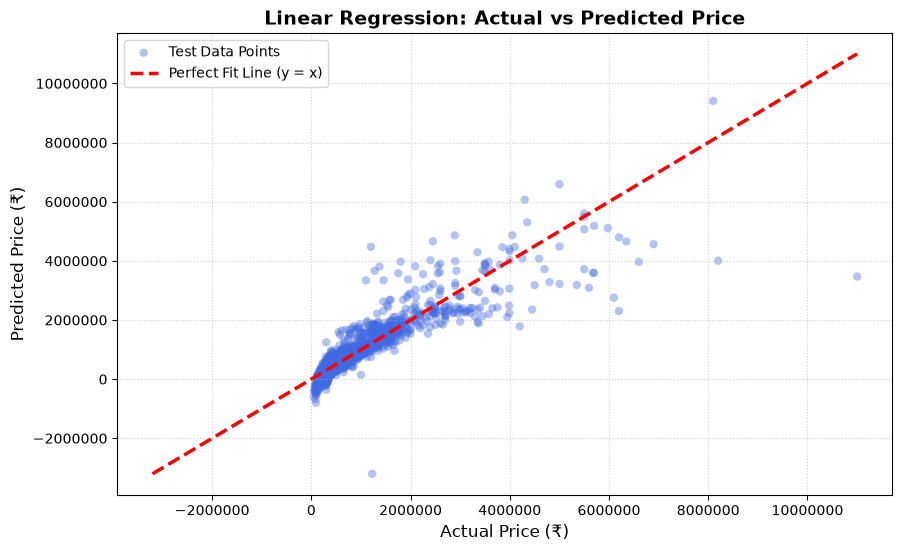

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Scatter actual vs predicted
plt.scatter(y_test, y_test_pred_lr, color='royalblue', alpha=0.4, edgecolor='none', label='Test Data Points')

# Perfect fit reference line (y = x)
min_val = min(y_test.min(), y_test_pred_lr.min())
max_val = max(y_test.max(), y_test_pred_lr.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2.5, label='Perfect Fit Line (y = x)')

plt.title('Linear Regression: Actual vs Predicted Price', fontsize=14, fontweight='bold')
plt.xlabel('Actual Price (₹)', fontsize=12)
plt.ylabel('Predicted Price (₹)', fontsize=12)
plt.ticklabel_format(style='plain')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()


## Applying Ridge Regression

In [36]:
from sklearn.linear_model import Ridge

# 1. Initialize and train Ridge Regression
ridge = Ridge(alpha=1.0)
ridge.fit(X_train_encoded, y_train)

# 2. Predict on both Train and Test sets
y_train_pred_ridge = ridge.predict(X_train_encoded)
y_test_pred_ridge = ridge.predict(X_test_encoded)

# 3. Accuracy Metrics
ridge_train_r2 = r2_score(y_train, y_train_pred_ridge)
ridge_test_r2 = r2_score(y_test, y_test_pred_ridge)
ridge_mae = mean_absolute_error(y_test, y_test_pred_ridge)
ridge_rmse = root_mean_squared_error(y_test, y_test_pred_ridge)

# 4. Compare Side-by-Side in a Clean DataFrame
comparison_df = pd.DataFrame({
    'Metric': ['Train R2', 'Test R2', 'MAE (₹)', 'RMSE (₹)'],
    'Linear Regression': [f"{lr_train_r2:.4f}", f"{lr_test_r2:.4f}", f"₹{lr_mae:,.0f}", f"₹{lr_rmse:,.0f}"],
    'Ridge Regression': [f"{ridge_train_r2:.4f}", f"{ridge_test_r2:.4f}", f"₹{ridge_mae:,.0f}", f"₹{ridge_rmse:,.0f}"]
})

display(comparison_df)


,Metric,Linear Regression,Ridge Regression
0,Train R2,0.8543,0.8080
1,Test R2,0.7790,0.7769
2,MAE (₹),"₹172,316","₹186,285"
3,RMSE (₹),"₹364,516","₹366,196"


In [37]:
## Lasso Regression 
from sklearn.linear_model import Lasso

# Train Lasso with an initial alpha
lasso = Lasso(alpha=100.0, max_iter=2000, random_state=42)
lasso.fit(X_train_encoded, y_train)

# Predictions & Metrics
y_train_pred_lasso = lasso.predict(X_train_encoded)
y_test_pred_lasso = lasso.predict(X_test_encoded)

lasso_train_r2 = r2_score(y_train, y_train_pred_lasso)
lasso_test_r2 = r2_score(y_test, y_test_pred_lasso)
lasso_mae = mean_absolute_error(y_test, y_test_pred_lasso)
lasso_rmse = root_mean_squared_error(y_test, y_test_pred_lasso)

# Count how many features Lasso zeroed out
zeroed_features = (lasso.coef_ == 0).sum()
total_features = len(lasso.coef_)
print(f"Lasso automatically zeroed out {zeroed_features} out of {total_features} features!")


Lasso automatically zeroed out 17 out of 131 features!


# Comparison

In [38]:
# Compare Linear vs Ridge vs Lasso side-by-side
linear_comparison_df = pd.DataFrame({
    'Metric': ['Train R²', 'Test R²', 'MAE (₹)', 'RMSE (₹)'],
    'Linear Regression': [f"{lr_train_r2:.4f}", f"{lr_test_r2:.4f}", f"₹{lr_mae:,.0f}", f"₹{lr_rmse:,.0f}"],
    'Ridge Regression': [f"{ridge_train_r2:.4f}", f"{ridge_test_r2:.4f}", f"₹{ridge_mae:,.0f}", f"₹{ridge_rmse:,.0f}"],
    'Lasso Regression': [f"{lasso_train_r2:.4f}", f"{lasso_test_r2:.4f}", f"₹{lasso_mae:,.0f}", f"₹{lasso_rmse:,.0f}"]
})

display(linear_comparison_df)


,Metric,Linear Regression,Ridge Regression,Lasso Regression
0,Train R²,0.8543,0.8080,0.8470
1,Test R²,0.7790,0.7769,0.7826
2,MAE (₹),"₹172,316","₹186,285","₹177,106"
3,RMSE (₹),"₹364,516","₹366,196","₹361,541"
